# Passaggio 4 (versione 2): spread e segnali per le 15 coppie

**Obiettivo.** Costruire lo spread e i segnali di ingresso e uscita per le **15 coppie della versione 2** ([coppie_2.ipynb](../01_selezione_coppie/coppie_2.ipynb)), sul solo **periodo di addestramento**. Sono l'input del Passaggio 5 (agente di notizie) e del Passaggio 6 (simulazione).

**Versione 1 e versione 2.** La versione 1 ha il suo notebook ([segnali_coppie.ipynb](segnali_coppie.ipynb)). Qui si applicano **le stesse regole e gli stessi parametri** alle coppie della versione 2, senza cercare parametri nuovi: così il confronto tra le due versioni riguarda solo le coppie, non il segnale.

**Scelte del gruppo applicate** (decisioni della versione 2):
| Tema | Scelta |
|---|---|
| Divisione train/test | Uguale per tutte le coppie, in date di calendario: **train fino al 16 settembre 2026, test dal 17 settembre**. Il test non viene calcolato |
| Spread | Logaritmo del rapporto tra i prezzi con **β = 1** (importi uguali sulle due gambe, senza leva) |
| Parametri | **Quelli della versione 1**, uguali per tutte: emivita 60 minuti, ingresso a \|z\| ≥ 2.0, uscita a \|z\| ≤ 0, stop a 3.5, tempo massimo 90 minuti. Nessuna ricerca di parametri sulla versione 2 |
| Orari | Nessun ingresso nei primi 15 e negli ultimi 30 minuti; tutto chiuso a fine giornata |
| Barre riempite | **Non si apre un trade se una delle due gambe ha la barra del segnale riempita** (prezzo vecchio); si conta quante occasioni si scartano |
| Salto di WDAY del 13 agosto | Lasciato com'è (movimento vero): nessun dato escluso. Si riporta cosa succede alla coppia CRM-WDAY quel giorno |
| Dividendi | Prezzi non aggiustati, limite da dichiarare |
| Costi | **Non considerati** (indicazione del docente): il guadagno è lordo |
| Frequenza | Barre da 1 minuto |

**Dove sono le regole.** Nel modulo [signals.py](../signals.py) (con `version=2` legge i file della versione 2), con commenti in italiano; le motivazioni di ogni regola sono in [segnale_mav.ipynb](segnale_mav.ipynb) e qui non si ripetono. Prima di ogni ingresso: il segnale si calcola alla chiusura della barra *t* e l'ordine si esegue all'apertura della barra *t+1*, per evitare di usare dati che nel momento della decisione non c'erano (lookahead bias).

| Parte | Cosa fa | Perché |
|---|---|---|
| 1 | Parametri | tutte le scelte in un posto solo |
| 2 | Le 15 coppie: dati e stazionarietà | descrizione, non filtro |
| 3 | Controlli: nessun lookahead, stessi risultati della versione 1 sulle coppie in comune | il codice deve fare quello che dichiara |
| 4 | Segnali e risultati coppia per coppia | quanti trade e quanto guadagno lordo |
| 5 | Da dove viene il guadagno | motivo di uscita, orario, barre riempite, giorno di WDAY |
| 6 | Salvataggio dei segnali | input del Passaggio 5 |
| 7 | Risultati (testo per il report) | numeri generati dai dati |

## 1. Parametri

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from statsmodels.tsa.stattools import adfuller, coint

# il notebook gira da src/04_segnali/: risali alla root del repo (quella che contiene data/) e rendi importabile src/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from signals import list_pairs, load_pair, zscore, run_rules, TRAIN_END, OPEN_SKIP, CLOSE_SKIP, MAX_HOLD, STOP_EXTRA

OUT_SIGNALS = ROOT / "data/processed/signals_15pairs_v2_train.csv"     # segnali del train delle 15 coppie, input del Passaggio 5
V1_SIGNALS = ROOT / "data/processed/signals_10pairs_train.csv"          # segnali della versione 1, per il controllo di coerenza e il confronto

# --- Parametri della versione 1, uguali per tutte le coppie (scelta del gruppo: nessuna ricerca nuova) ---
HL, ENTRY, EXIT = 60, 2.0, 0.0      # emivita della EMA (minuti), soglia di ingresso e di uscita in unita di z
VERSION = 2

## 2. Le 15 coppie: dati e stazionarietà

Per ogni coppia: giorni di train e di test, quota di minuti con una gamba ferma (almeno uno dei due titoli senza scambi), oscillazione dello spread dentro la giornata e tra giorni, e due test sullo spread del train (ADF e cointegrazione di Engle-Granger, su barre da 5 minuti per ridurre il rumore). **Sono descrizioni, non filtri**: la lista delle coppie è già fissata.

In [2]:
pairs = list_pairs(VERSION)
data = {p: load_pair(p, VERSION) for p in pairs.pair}

rows = []
for p, d in data.items():
    tr = d.is_train
    sub = np.arange(len(d.S))[tr][::5]
    logA, logB = np.log(d.cA[sub]), np.log(d.cB[sub])
    s5 = d.S.iloc[sub]
    phi = np.polyfit(s5.shift(1).dropna(), s5.iloc[1:], 1)[0]
    daily = d.S[tr].groupby(d.ts[tr].normalize())
    rows.append(dict(pair=p, giorni_train=len(set(d.ts[tr].normalize())), giorni_test=len(set(d.ts[~tr].normalize())),
                     riempite_A=d.filled_A[tr].mean(), riempite_B=d.filled_B[tr].mean(), gamba_ferma=d.stale[tr].mean(),
                     std_dentro_giorno_bps=daily.std().mean() * 1e4, std_tra_giorni_bps=daily.mean().std() * 1e4,
                     adf_p=adfuller(s5, regression="c", autolag="AIC", result_object=False)[1], coint_p=coint(logA, logB, trend="c")[1],
                     emivita_giorni=(-np.log(2) / np.log(phi) / 78) if 0 < phi < 1 else np.inf))
info = pd.DataFrame(rows).set_index("pair")
info.style.format({"riempite_A": "{:.1%}", "riempite_B": "{:.1%}", "gamba_ferma": "{:.1%}", "std_dentro_giorno_bps": "{:.0f}", "std_tra_giorni_bps": "{:.0f}",
                   "adf_p": "{:.2f}", "coint_p": "{:.3f}", "emivita_giorni": "{:.1f}"})

,giorni_train,giorni_test,riempite_A,riempite_B,gamba_ferma,std_dentro_giorno_bps,std_tra_giorni_bps,adf_p,coint_p,emivita_giorni
pair,,,,,,,,,,
MA-V,64,32,9.5%,1.5%,10.6%,18,192,0.44,0.034,5.1
CSX-UNP,60,31,2.1%,41.4%,42.3%,25,192,0.32,0.152,3.5
PYPL-XYZ,64,32,1.0%,12.9%,13.6%,58,1030,0.49,0.193,9.1
HD-LOW,60,31,6.2%,33.5%,36.5%,24,199,0.08,0.561,3.5
DHR-TMO,60,31,27.1%,23.4%,41.2%,37,506,0.46,0.119,6.2
CRM-WDAY,64,32,2.3%,12.5%,14.3%,69,856,0.61,0.912,12.6
JPM-WFC,64,32,1.5%,2.4%,3.8%,30,254,0.31,0.582,5.5
NXPI-TXN,64,32,21.5%,7.2%,26.1%,48,584,0.47,0.303,9.2
ELV-UNH,64,32,35.2%,4.0%,37.0%,41,591,0.85,0.131,17.6


## 3. Controlli

Il codice dei segnali è lo stesso della versione 1: bisogna verificare che faccia quello che dichiara. Due controlli:
1. **Nessun lookahead.** Lo z-score di ogni barra non cambia se si tolgono le barre successive, per ogni coppia.
2. **Stessi risultati della versione 1 sulle coppie in comune.** Le coppie MA-V, CSX-UNP, PYPL-XYZ, HD-LOW e KO-PEP sono in entrambe le versioni, con gli stessi dati puliti e gli stessi parametri: i trade devono coincidere con quelli di `signals_10pairs_train.csv`.

In [3]:
for p, d in data.items():
    n_cut = len(d.S) // 2
    assert np.allclose(zscore(d.S.iloc[:n_cut], HL), zscore(d.S, HL)[:n_cut], equal_nan=True), f"{p}: lo z-score usa dati futuri"
print(f"OK: lo z-score di ogni barra non dipende dalle barre successive ({len(data)} coppie)")

coerenza = None
if V1_SIGNALS.exists():
    v1 = pd.read_csv(V1_SIGNALS, parse_dates=["t_signal", "t_entry", "t_exit"])
    common = sorted(set(v1.pair) & set(data))
    res = []
    for p in common:
        t_new, _ = run_rules(data[p], zscore(data[p].S, HL), ENTRY, EXIT)
        old = v1[v1.pair == p].sort_values("t_signal").reset_index(drop=True)
        same = len(t_new) == len(old) and (t_new.t_signal.values == old.t_signal.values).all() and np.allclose(t_new.gross_bps.values, old.gross_bps.values)
        res.append(dict(pair=p, trade_v2=len(t_new), trade_v1=len(old), identici=bool(same)))
    coerenza = pd.DataFrame(res).set_index("pair")
    print("Controllo con la versione 1 sulle coppie in comune:"); print(coerenza.to_string())
else:
    print(f"Controllo saltato: manca {V1_SIGNALS.name}")

OK: lo z-score di ogni barra non dipende dalle barre successive (15 coppie)


Controllo con la versione 1 sulle coppie in comune:
          trade_v2  trade_v1  identici
pair                                  
CSX-UNP         61        61      True
HD-LOW          65        65      True
KO-PEP          68        68      True
MA-V            75        75      True
PYPL-XYZ        60        60      True


## 4. Segnali e risultati coppia per coppia

Si applicano le regole con i parametri della versione 1 a ogni coppia, solo sul train. Il guadagno è **lordo**, senza costi. L'errore standard assume trade indipendenti; in realtà trade di coppie dello stesso settore nello stesso giorno sono legati, quindi l'incertezza vera è un po' maggiore.

In [4]:
all_trades, rows = [], []
for p, d in data.items():
    tr, blocked = run_rules(d, zscore(d.S, HL), ENTRY, EXIT)
    all_trades.append(tr)
    rows.append(dict(pair=p, trade=len(tr), per_giorno=len(tr) / info.loc[p, "giorni_train"], lordo_medio_bps=tr.gross_bps.mean() if len(tr) else np.nan,
                     errore_std_bps=tr.gross_bps.std() / np.sqrt(len(tr)) if len(tr) > 1 else np.nan, in_positivo=(tr.gross_bps > 0).mean() if len(tr) else np.nan,
                     uscita_per_tempo=(tr.exit_reason == "tempo").mean() if len(tr) else np.nan, scartate_gamba_ferma=blocked,
                     prezzo_esec_vecchio=int(tr.exec_price_stale.sum()) if len(tr) else 0))
trades = pd.concat(all_trades, ignore_index=True)
per_pair = pd.DataFrame(rows).set_index("pair")

print(f"Parametri (uguali per tutte, della versione 1): emivita {HL} minuti, ingresso |z| >= {ENTRY}, uscita |z| <= {EXIT}, stop |z| >= {ENTRY + STOP_EXTRA}, tempo massimo {MAX_HOLD} minuti")
print(f"TOTALE: {len(trades)} trade, lordo medio {trades.gross_bps.mean():.1f} bps (errore standard {trades.gross_bps.std() / np.sqrt(len(trades)):.1f}), mediano {trades.gross_bps.median():.1f}, in positivo {(trades.gross_bps > 0).mean():.0%}")
print(f"coppie con guadagno medio positivo: {(per_pair.lordo_medio_bps > 0).sum()} su {len(per_pair)}; barre candidate scartate per gamba ferma: {per_pair.scartate_gamba_ferma.sum()}")
per_pair.style.format({"per_giorno": "{:.2f}", "lordo_medio_bps": "{:.1f}", "errore_std_bps": "{:.1f}", "in_positivo": "{:.0%}", "uscita_per_tempo": "{:.0%}"})

Parametri (uguali per tutte, della versione 1): emivita 60 minuti, ingresso |z| >= 2.0, uscita |z| <= 0.0, stop |z| >= 3.5, tempo massimo 90 minuti
TOTALE: 973 trade, lordo medio 7.4 bps (errore standard 2.0), mediano 10.8, in positivo 60%
coppie con guadagno medio positivo: 12 su 15; barre candidate scartate per gamba ferma: 233


,trade,per_giorno,lordo_medio_bps,errore_std_bps,in_positivo,uscita_per_tempo,scartate_gamba_ferma,prezzo_esec_vecchio
pair,,,,,,,,
MA-V,75,1.17,7.5,2.5,64%,36%,5,1
CSX-UNP,61,1.02,6.8,4.2,56%,41%,40,25
PYPL-XYZ,60,0.94,29.6,14.0,63%,47%,1,3
HD-LOW,65,1.08,4.4,4.1,68%,31%,35,12
DHR-TMO,62,1.03,6.6,6.5,58%,44%,36,21
CRM-WDAY,60,0.94,28.2,19.1,60%,48%,12,3
JPM-WFC,65,1.02,4.3,5.9,62%,38%,0,2
NXPI-TXN,68,1.06,-2.2,7.3,50%,44%,26,9
ELV-UNH,59,0.92,10.8,7.4,58%,58%,18,16


## 5. Da dove viene il guadagno

Quattro controlli descrittivi, gli stessi della versione 1: come escono i trade, a che ora entrano, quanti sono eseguiti a un prezzo vecchio, e cosa succede il giorno del salto di WDAY (13 agosto), che abbiamo scelto di **non** escludere. Non cambiano nulla ai segnali: servono a capire e a scrivere il report.

Motivo di uscita:
               trade  lordo medio (bps)
exit_reason                            
fine_giornata     56                0.3
rientro          464               38.8
stop              31              -32.1
tempo            422              -23.2

Fascia oraria dell'ingresso (minuti dall'apertura):
         trade  lordo medio (bps)
fascia                           
15-30      457               11.4
30-60      120               10.1
60-120     110                1.0
120-240    102               -3.8
240-390    184                5.9

entrate nei minuti 15-30: 457 trade su 973 (47%), 72% del guadagno lordo totale, lordo medio 11.4 bps
entrate dopo i 30 minuti: 516 trade, lordo medio 3.9 bps (errore standard 2.6)
eseguiti a un prezzo vecchio (barra t+1 riempita): 129 trade su 973
trade con un segnale di un'altra coppia nello stesso minuto: 30%
senza PYPL-XYZ (la coppia col guadagno medio piu alto): 913 trade, lordo medio 6.0 bps (errore standard 2.0)

CRM-WDAY il 13 agosto (sal

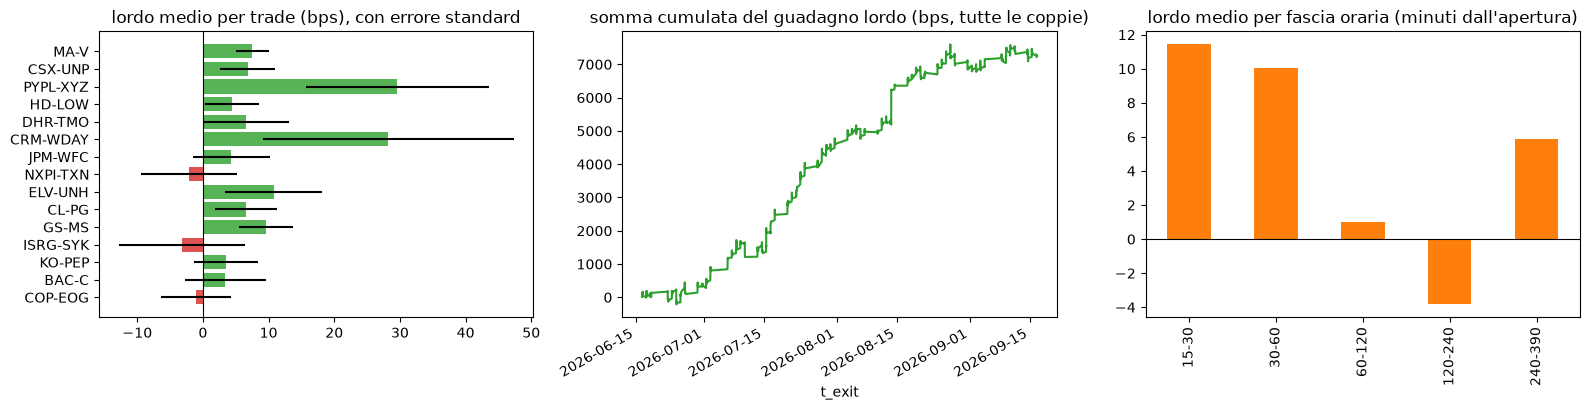

In [5]:
trades["fascia"] = pd.cut(trades.minute_of_day, [0, 30, 60, 120, 240, 390], right=True, labels=["15-30", "30-60", "60-120", "120-240", "240-390"], include_lowest=True)
by_exit = trades.groupby("exit_reason").gross_bps.agg(["size", "mean"]).round(1).rename(columns={"size": "trade", "mean": "lordo medio (bps)"})
by_slot = trades.groupby("fascia", observed=False).gross_bps.agg(["size", "mean"]).round(1).rename(columns={"size": "trade", "mean": "lordo medio (bps)"})
print("Motivo di uscita:"); print(by_exit)
print("\nFascia oraria dell'ingresso (minuti dall'apertura):"); print(by_slot)

early = trades[trades.minute_of_day <= 30]; late = trades[trades.minute_of_day > 30]
early_share = early.gross_bps.sum() / trades.gross_bps.sum()
print(f"\nentrate nei minuti 15-30: {len(early)} trade su {len(trades)} ({len(early) / len(trades):.0%}), {early_share:.0%} del guadagno lordo totale, lordo medio {early.gross_bps.mean():.1f} bps")
print(f"entrate dopo i 30 minuti: {len(late)} trade, lordo medio {late.gross_bps.mean():.1f} bps (errore standard {late.gross_bps.std() / np.sqrt(len(late)):.1f})")
n_stale = int(trades.exec_price_stale.sum())
print(f"eseguiti a un prezzo vecchio (barra t+1 riempita): {n_stale} trade su {len(trades)}")
overlap = trades.groupby("t_signal").pair.transform("size").gt(1).mean()
print(f"trade con un segnale di un'altra coppia nello stesso minuto: {overlap:.0%}")

best_pair = per_pair.lordo_medio_bps.idxmax()
rest = trades[trades.pair != best_pair]
print(f"senza {best_pair} (la coppia col guadagno medio piu alto): {len(rest)} trade, lordo medio {rest.gross_bps.mean():.1f} bps (errore standard {rest.gross_bps.std() / np.sqrt(len(rest)):.1f})")

wd = trades[(trades.pair == "CRM-WDAY") & (trades.t_signal.dt.date == pd.Timestamp("2026-08-13").date())]
print(f"\nCRM-WDAY il 13 agosto (salto di WDAY): {len(wd)} trade, lordo " + (", ".join(f"{g:.0f} bps ({r})" for g, r in zip(wd.gross_bps, wd.exit_reason)) if len(wd) else "nessun trade"))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].barh(per_pair.index, per_pair.lordo_medio_bps, xerr=per_pair.errore_std_bps, color=np.where(per_pair.lordo_medio_bps > 0, "tab:green", "tab:red"), alpha=0.8)
ax[0].axvline(0, color="k", lw=0.8); ax[0].set_title("lordo medio per trade (bps), con errore standard"); ax[0].invert_yaxis()
trades.sort_values("t_exit").set_index("t_exit").gross_bps.cumsum().plot(ax=ax[1], color="tab:green"); ax[1].set_title("somma cumulata del guadagno lordo (bps, tutte le coppie)")
trades.groupby("fascia", observed=False).gross_bps.mean().plot.bar(ax=ax[2], color="tab:orange"); ax[2].axhline(0, color="k", lw=0.8)
ax[2].set_title("lordo medio per fascia oraria (minuti dall'apertura)"); ax[2].set_xlabel("")
plt.tight_layout(); plt.show()

## 6. Salvataggio dei segnali del train

Tabella dei segnali di tutte le coppie: input del Passaggio 5. Stesse colonne della versione 1 (`pair`, `ticker_A` e `ticker_B`, orari del segnale, dell'ingresso e dell'uscita in ora di New York, `direction`, `z_signal`, `leg_piu_mosso`, rendimenti degli ultimi 30 minuti, prezzi, `exit_reason`, `gross_bps` lordo senza costi, `exec_price_stale`, parametri). File **separato** da quello della versione 1; cartella ignorata da git.

In [6]:
out = trades.sort_values(["t_signal", "pair"]).reset_index(drop=True)
out["signal_id"] = out.index
out["ema"] = "continua"
out["hl_min"], out["entry_z"], out["exit_z"], out["stop_z"] = HL, ENTRY, EXIT, ENTRY + STOP_EXTRA
cols = ["signal_id", "pair", "ticker_A", "ticker_B", "t_signal", "t_entry", "t_exit", "direction", "z_signal", "leg_piu_mosso", "ret_A_30m", "ret_B_30m",
        "price_A_in", "price_B_in", "price_A_out", "price_B_out", "exit_reason", "gross_bps", "minutes_in_trade", "exec_price_stale", "ema", "hl_min", "entry_z", "exit_z", "stop_z"]
assert out.t_exit.max() < pd.Timestamp(TRAIN_END) + pd.Timedelta(days=1), "il file dei segnali contiene giorni di test"
OUT_SIGNALS.parent.mkdir(parents=True, exist_ok=True)
out[cols].to_csv(OUT_SIGNALS, index=False)
print(f"salvati {len(out)} segnali di {out.pair.nunique()} coppie in {OUT_SIGNALS.name} (ultimo giorno: {out.t_exit.max().date()}, taglio del train: {TRAIN_END})")
out[cols].head()

salvati 973 segnali di 15 coppie in signals_15pairs_v2_train.csv (ultimo giorno: 2026-09-16, taglio del train: 2026-09-16)


,signal_id,pair,ticker_A,ticker_B,t_signal,t_entry,t_exit,direction,z_signal,leg_piu_mosso,...,price_B_out,exit_reason,gross_bps,minutes_in_trade,exec_price_stale,ema,hl_min,entry_z,exit_z,stop_z
0,0,COP-EOG,COP,EOG,2026-06-16 10:31:00,2026-06-16 10:32:00,2026-06-16 10:55:00,long COP / short EOG,-2.194212,EOG,...,130.780,rientro,13.788510,23.0,False,continua,60,2.0,0.0,3.5
1,1,KO-PEP,KO,PEP,2026-06-16 11:04:00,2026-06-16 11:05:00,2026-06-16 11:19:00,short KO / long PEP,2.035824,PEP,...,145.650,rientro,31.056741,14.0,False,continua,60,2.0,0.0,3.5
2,2,MA-V,MA,V,2026-06-16 11:04:00,2026-06-16 11:05:00,2026-06-16 11:23:00,short MA / long V,2.073157,MA,...,330.275,rientro,25.179270,18.0,False,continua,60,2.0,0.0,3.5
3,3,COP-EOG,COP,EOG,2026-06-16 11:31:00,2026-06-16 11:32:00,2026-06-16 12:20:00,long COP / short EOG,-2.469532,EOG,...,131.460,rientro,19.471550,48.0,False,continua,60,2.0,0.0,3.5
4,4,GS-MS,GS,MS,2026-06-16 11:45:00,2026-06-16 11:46:00,2026-06-16 12:12:00,long GS / short MS,-2.178510,GS,...,221.070,rientro,38.294415,26.0,False,continua,60,2.0,0.0,3.5


## 7. Risultati (testo per il report)

La cella seguente genera il testo dai risultati del notebook: se si cambiano dati o parametri, i numeri si aggiornano da soli.

In [7]:
from IPython.display import Markdown, display

v1_line = ""
if V1_SIGNALS.exists():
    v1g = v1.gross_bps
    v1_line = f"- **Confronto con la versione 1** (stessi parametri): {len(v1)} trade, {v1g.mean():.1f} bps lordi in media (errore standard {v1g.std() / np.sqrt(len(v1)):.1f}); versione 2: {len(trades)} trade, {trades.gross_bps.mean():.1f} bps."
coer_line = ""
if coerenza is not None:
    coer_line = f"- **Controllo di coerenza**: sulle {len(coerenza)} coppie in comune con la versione 1 i trade sono " + ("identici" if coerenza.identici.all() else "NON identici: " + ", ".join(coerenza.index[~coerenza.identici])) + "."
se = trades.gross_bps.std() / np.sqrt(len(trades))
pos = per_pair.lordo_medio_bps.sort_values()
top = per_pair.sort_values("lordo_medio_bps", ascending=False).head(3)
bot = per_pair.sort_values("lordo_medio_bps").head(3)
exit_txt = ", ".join(f"{k} {int(r['trade'])} trade ({r['lordo medio (bps)']:+.0f} bps)" for k, r in by_exit.iterrows())
stale_pairs = per_pair.gamba_ferma if "gamba_ferma" in per_pair else info.gamba_ferma
fermi = info.gamba_ferma.sort_values(ascending=False).head(4)
lines = [
    "### Cosa abbiamo fatto",
    f"Abbiamo costruito lo spread di ognuna delle {len(pairs)} coppie della versione 2 come differenza dei logaritmi dei prezzi (importi uguali sulle due gambe, β = 1) e calcolato lo z-score con media e deviazione standard esponenziali (emivita {HL} minuti, continua su tutta la serie). Si entra alla barra successiva se |z| ≥ {ENTRY}, si esce per rientro (|z| ≤ {EXIT}), stop (|z| ≥ {ENTRY + STOP_EXTRA}), tempo massimo ({MAX_HOLD} minuti) o fine giornata. Parametri **uguali a quelli della versione 1**, nessuna ricerca nuova. Solo periodo di addestramento (16 giugno - 16 settembre 2026), costi esclusi.",
    "",
    "### Perche",
    "Il segnale e lo stesso della versione 1 per poter confrontare le due liste di coppie senza che cambi anche la regola; il test (dal 17 settembre) resta inutilizzato e non si cercano parametri nuovi per non adattarli ai dati. Non si apre un trade se una gamba ha la barra riempita, perche altrimenti lo spread si allarga solo perche un titolo e fermo. I costi non si considerano per indicazione del docente.",
    "",
    "### Risultati sul train",
    f"- **Totale**: {len(trades)} trade ({len(trades) / len(pairs) / info.giorni_train.mean():.2f} al giorno per coppia), guadagno **lordo** medio {trades.gross_bps.mean():.1f} bps (errore standard {se:.1f}), mediano {trades.gross_bps.median():.1f}, {(trades.gross_bps > 0).mean():.0%} in positivo; {int((per_pair.lordo_medio_bps > 0).sum())} coppie su {len(per_pair)} con guadagno medio positivo.",
    "- **Coppie migliori**: " + ", ".join(f"{p} {r.lordo_medio_bps:.1f} bps ({int(r.trade)} trade, errore {r.errore_std_bps:.1f})" for p, r in top.iterrows()) + ". **Peggiori**: " + ", ".join(f"{p} {r.lordo_medio_bps:.1f} bps ({int(r.trade)} trade)" for p, r in bot.iterrows()) + ".",
    f"- **Senza {best_pair}** (la coppia col guadagno medio piu alto): {len(rest)} trade, {rest.gross_bps.mean():.1f} bps (errore {rest.gross_bps.std() / np.sqrt(len(rest)):.1f}).",
    f"- **Come escono i trade**: {exit_txt}.",
    f"- **Orario**: le entrate dei minuti 15-30 sono {len(early)} trade ({len(early) / len(trades):.0%}) e producono il {early_share:.0%} del guadagno lordo (lordo medio {early.gross_bps.mean():.1f} bps); dopo i 30 minuti {len(late)} trade fanno {late.gross_bps.mean():.1f} bps (errore {late.gross_bps.std() / np.sqrt(len(late)):.1f}).",
    f"- **Barre riempite**: {n_stale} trade ({n_stale / len(trades):.0%}) sono eseguiti alla barra successiva quando questa e riempita (prezzo non di scambio vero) e {int(per_pair.scartate_gamba_ferma.sum())} occasioni sono scartate per gamba ferma. Coppie con la gamba ferma piu spesso: " + ", ".join(f"{p} {v:.0%}" for p, v in fermi.items()) + ".",
    f"- **Stazionarieta sul train**: Engle-Granger sotto 0.05 per {int((info.coint_p < 0.05).sum())} coppie su {len(info)}; ADF sotto 0.05 per {int((info.adf_p < 0.05).sum())} su {len(info)}. Emivita dello spread da {info.emivita_giorni.min():.1f} a {info.emivita_giorni.replace(np.inf, np.nan).max():.1f} giorni.",
    "- **Giorno del salto di WDAY (13 agosto)**: " + (f"CRM-WDAY ha {len(wd)} trade quel giorno, con guadagno lordo " + ", ".join(f"{g:.0f} bps" for g in wd.gross_bps) + f". Il trade piu grande ({wd.gross_bps.max():.0f} bps) vale il {wd.gross_bps.max() / trades.gross_bps.sum():.0%} del guadagno lordo totale delle {len(pairs)} coppie; senza di esso la media scenderebbe a {(trades.gross_bps.sum() - wd.gross_bps.max()) / (len(trades) - 1):.1f} bps e quella di CRM-WDAY a {(trades[trades.pair == 'CRM-WDAY'].gross_bps.sum() - wd.gross_bps.max()) / (len(trades[trades.pair == 'CRM-WDAY']) - 1):.1f} bps. Per scelta del gruppo il giorno non e escluso: il dato e riportato qui perche pesa molto sul risultato." if len(wd) else "CRM-WDAY non ha trade quel giorno."),
    f"- **Segnali sovrapposti**: il {overlap:.0%} dei trade ha un segnale di un'altra coppia nello stesso minuto: i trade non sono indipendenti e gli errori standard sono sottostimati.",
    v1_line, coer_line,
    "",
    "### Cosa significa",
    "- Il guadagno e lordo (nessun costo, per indicazione del docente) e va letto insieme all'errore standard: coppie con pochi trade e errori grandi sono indistinguibili da zero.",
    "- Se la maggior parte del guadagno viene dai primi 30 minuti, e soprattutto il rientro del gap della notte, non un movimento dentro la giornata: da dichiarare nel report.",
    "- Il test (dal 17 settembre) non e stato calcolato.",
]
display(Markdown("\n".join(l for l in lines if l is not None)))

### Cosa abbiamo fatto
Abbiamo costruito lo spread di ognuna delle 15 coppie della versione 2 come differenza dei logaritmi dei prezzi (importi uguali sulle due gambe, β = 1) e calcolato lo z-score con media e deviazione standard esponenziali (emivita 60 minuti, continua su tutta la serie). Si entra alla barra successiva se |z| ≥ 2.0, si esce per rientro (|z| ≤ 0.0), stop (|z| ≥ 3.5), tempo massimo (90 minuti) o fine giornata. Parametri **uguali a quelli della versione 1**, nessuna ricerca nuova. Solo periodo di addestramento (16 giugno - 16 settembre 2026), costi esclusi.

### Perche
Il segnale e lo stesso della versione 1 per poter confrontare le due liste di coppie senza che cambi anche la regola; il test (dal 17 settembre) resta inutilizzato e non si cercano parametri nuovi per non adattarli ai dati. Non si apre un trade se una gamba ha la barra riempita, perche altrimenti lo spread si allarga solo perche un titolo e fermo. I costi non si considerano per indicazione del docente.

### Risultati sul train
- **Totale**: 973 trade (1.04 al giorno per coppia), guadagno **lordo** medio 7.4 bps (errore standard 2.0), mediano 10.8, 60% in positivo; 12 coppie su 15 con guadagno medio positivo.
- **Coppie migliori**: PYPL-XYZ 29.6 bps (60 trade, errore 14.0), CRM-WDAY 28.2 bps (60 trade, errore 19.1), ELV-UNH 10.8 bps (59 trade, errore 7.4). **Peggiori**: ISRG-SYK -3.2 bps (63 trade), NXPI-TXN -2.2 bps (68 trade), COP-EOG -1.0 bps (61 trade).
- **Senza PYPL-XYZ** (la coppia col guadagno medio piu alto): 913 trade, 6.0 bps (errore 2.0).
- **Come escono i trade**: fine_giornata 56 trade (+0 bps), rientro 464 trade (+39 bps), stop 31 trade (-32 bps), tempo 422 trade (-23 bps).
- **Orario**: le entrate dei minuti 15-30 sono 457 trade (47%) e producono il 72% del guadagno lordo (lordo medio 11.4 bps); dopo i 30 minuti 516 trade fanno 3.9 bps (errore 2.6).
- **Barre riempite**: 129 trade (13%) sono eseguiti alla barra successiva quando questa e riempita (prezzo non di scambio vero) e 233 occasioni sono scartate per gamba ferma. Coppie con la gamba ferma piu spesso: CSX-UNP 42%, DHR-TMO 41%, ELV-UNH 37%, HD-LOW 37%.
- **Stazionarieta sul train**: Engle-Granger sotto 0.05 per 1 coppie su 15; ADF sotto 0.05 per 0 su 15. Emivita dello spread da 2.9 a 17.6 giorni.
- **Giorno del salto di WDAY (13 agosto)**: CRM-WDAY ha 5 trade quel giorno, con guadagno lordo -2 bps, 7 bps, 72 bps, -42 bps, 985 bps. Il trade piu grande (985 bps) vale il 14% del guadagno lordo totale delle 15 coppie; senza di esso la media scenderebbe a 6.4 bps e quella di CRM-WDAY a 12.0 bps. Per scelta del gruppo il giorno non e escluso: il dato e riportato qui perche pesa molto sul risultato.
- **Segnali sovrapposti**: il 30% dei trade ha un segnale di un'altra coppia nello stesso minuto: i trade non sono indipendenti e gli errori standard sono sottostimati.
- **Confronto con la versione 1** (stessi parametri): 624 trade, 6.8 bps lordi in media (errore standard 2.1); versione 2: 973 trade, 7.4 bps.
- **Controllo di coerenza**: sulle 5 coppie in comune con la versione 1 i trade sono identici.

### Cosa significa
- Il guadagno e lordo (nessun costo, per indicazione del docente) e va letto insieme all'errore standard: coppie con pochi trade e errori grandi sono indistinguibili da zero.
- Se la maggior parte del guadagno viene dai primi 30 minuti, e soprattutto il rientro del gap della notte, non un movimento dentro la giornata: da dichiarare nel report.
- Il test (dal 17 settembre) non e stato calcolato.